### With the use of a spring-powered launcher of spring coefficient 20 N/m, a ping-pong ball is launched into a cup 1.4 meters away (D = 0.092 m). During the launch, there is wind blowing in the same direction the ball is going at 9 m/s. What is the compression of the spring such that the ping-pong ball successfully makes it into the cup?

(Standard ping-pong ball size and mass: D = 0.04 m, 0.0027 kg)

In [1]:
# this code block imports necessary libraries. 
# numpy for assisting in working with values, 
# matplotlib for graphing
import numpy as np 
import matplotlib.pyplot as plt

### How will the velocity v used in the drag force expression be obtained?

The expression for both linear and quadratic drag force requires you to take into consideration the relative velocity of the moving object through the fluid (in this case, the ping-pong ball through the air.) <br>

When considering drag in the x direction: $v_{x, relative} = v_{wind} - v_x$<br>
When considering drag in the y direction: $v_{y, relative} = v_{y}$. This is because the wind is only blowing in the x direction; therefore, there is no vertical component. 

### Is it expected that the drag will be linear, quadratic, or both? What is the Reynolds number for this scenerio?

Reynolds number:
$R = \frac{\rho \ v_{relative} \ D}{\xi}$ <br>
Where $\rho$ is the air density, v is the velocity, D is the object diameter, and $\xi$ is a constant dependant on the medium; for air, using the given values in  Taylor, it is 1.2.

R will change as the ball velocity changes, but in the case of the ping-pong ball, it will always be considerably above 1, meaning that only quadratic drag will have to be minded in this problem. 

$R = \frac{\rho \ v_{relative} \ D}{\xi} = \frac{(1.2 kg/m^3)(v)(0.04 m)}{(1.5e-5)} = 3200v$ <br>

The velocity will always be above 1.

### Explain the drag coefficients used in this problem.

$\xi$ was determined using the values of the linear and quadratic drag coefficient values of air; 1.6e-4 $\frac{Ns}{m^2}$ and 0.25 $\frac{Ns^2}{m^4}$ respectively.

In [3]:
# define parameters
k = 20.0 # N/m
mass = 0.00273 # kg
D = 0.040 # m
g = 9.8 # m/s^2

cup_radius = 0.046 # m

v_wind = 9.0 # m/s
xi = 1.2 # (constant for linear drag coeff / quadratic drag coeff for air)

In [5]:
def rhs(t, s, vw):
    x, y, vx, vy = s
    ux, uy = vx - vw, vy   # finds the relative velocity
    sp = np.hypot(ux, uy)  # velocity magnitude
    F = (b + c*sp)         # f = (b + c|v_rel|) v_rel
    return [vx, vy, -F*ux/m, -g - F*uy/m] # returns velocities and derivatives

# stop solving when the ball enters the cup (when y becomes negative)
def hit_ground(t, s, vw): return s[1]
hit_ground.terminal, hit_ground.direction = True, -1   # only on the way down

def fly(dx, vw=vw0, **kw):
    v0 = dx*np.sqrt(k/m)                 # (1/2)k dx^2 = (1/2) m v0^2
    opts = dict(rtol=1e-10, atol=1e-12, method="DOP853", dense_output=True)
    opts.update(kw)
    sol = solve_ivp(rhs, [0, 10], [0, 0, 0, v0], args=(vw,),
                    events=hit_ground, **opts)
    return sol.y_events[0][0][0], sol    # landing x, full solution


dx = 3.776 cm, v0 = 3.250 m/s, T = 0.585 s, landing x = 1.400000 m


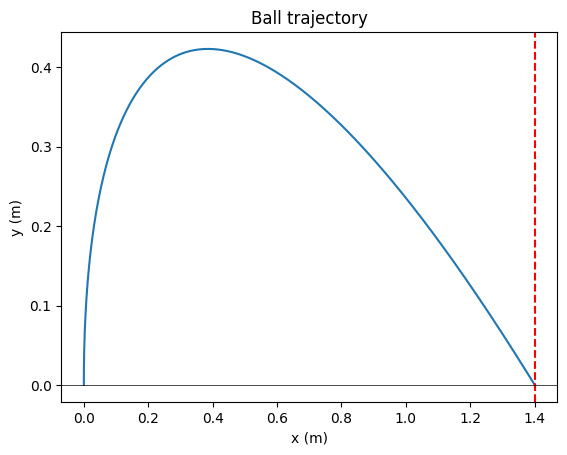

1e-06 1.7742163960221546e-08
1e-08 -3.4384717295665723e-10
1e-10 -2.2870594307278225e-14
1e-12 3.745892485085278e-13
loose RK45 (rtol 1e-3): -6.6087252847957245e-06


In [6]:
# the "numerical solver"

dx = brentq(lambda d: fly(d)[0] - X, 0.005, 0.1, xtol=1e-12)
xland, sol = fly(dx)
print(f"dx = {dx*100:.3f} cm, v0 = {dx*np.sqrt(k/m):.3f} m/s, "
      f"T = {sol.t_events[0][0]:.3f} s, landing x = {xland:.6f} m")

# # sanity check: no drag, no wind -> vacuum formulas
# b_save, c_save = b, c
# b = c = 0.0
# v0 = dx*np.sqrt(k/m)
# _, s0 = fly(dx, vw=0.0)
# print("vacuum check: T", s0.t_events[0][0], "vs", 2*v0/g,
#       "| ymax", s0.y[1].max(), "vs", v0**2/(2*g))
# b, c = b_save, c_save

# # ---- item 2/3: which drag term matters? ----
# v0 = dx*np.sqrt(k/m)
# print("Re (wind speed)  =", D*vw0/nu)          # ~2e4
# print("Re (launch speed)=", D*v0/nu)           # ~9e3
# print("quad/lin ratio at 9 m/s =", c*9/b)      # ~560 -> quadratic dominates

# ---- item 5: trajectory plot ----
t = np.linspace(0, sol.t_events[0][0], 400)
x, y = sol.sol(t)[0], sol.sol(t)[1]
plt.plot(x, y); plt.axvline(X, ls="--", c="r")
plt.axhline(0, c="k", lw=.5)
plt.xlabel("x (m)"); plt.ylabel("y (m)"); plt.title("Ball trajectory")
plt.show()

# # ---- item 6: precision / repeatability ----
# d_hi = brentq(lambda d: fly(d)[0] - (X+R), 0.005, 0.1) - dx
# d_lo = dx - brentq(lambda d: fly(d)[0] - (X-R), 0.005, 0.1)
# w_hi = brentq(lambda w: fly(dx, w)[0] - (X+R), 5, 15) - vw0
# w_lo = vw0 - brentq(lambda w: fly(dx, w)[0] - (X-R), 3, 9)
# print(f"dx tolerance: +{d_hi*1e3:.2f} mm / -{d_lo*1e3:.2f} mm")
# print(f"wind tolerance: +{w_hi:.2f} / -{w_lo:.2f} m/s")

# ---- item 7: numerical convergence ----
for rt in [1e-6, 1e-8, 1e-10, 1e-12]:
    print(rt, fly(dx, rtol=rt, atol=rt*1e-2)[0] - X)
print("loose RK45 (rtol 1e-3):", fly(dx, rtol=1e-3, atol=1e-6, method="RK45")[0] - X)